In [11]:
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from similarities import (
    dense_matrix,
    df,
    get_article_vectors,
    recommend_articles,
    tfidf,
)

In [ ]:
def plot_corpus_statistics(df, dense_matrix):

    _, axes = plt.subplots(2, 2, figsize=(14, 10))

    sns.histplot(df["token_count"], bins=40, kde=True, ax=axes[0, 0], color="#2b5c8f")
    axes[0, 0].set_title("Distribution of Document Lengths (Tokens)")
    axes[0, 0].set_xlabel("Number of Tokens")
    axes[0, 0].set_ylabel("Article Count")

    sns.histplot(df["vocab_size"], bins=40, kde=True, ax=axes[0, 1], color="#4b8b3b")
    axes[0, 1].set_title("Unique Vocabulary Size per Document")
    axes[0, 1].set_xlabel("Unique Words")
    axes[0, 1].set_ylabel("Article Count")

    all_words = " ".join(df["text_lemmatized"]).split()
    word_counts = Counter(all_words).most_common(20)
    words, counts = zip(*word_counts)

    axes[1, 0].barh(words[::-1], counts[::-1], color="#9b4d8f")
    axes[1, 0].set_title("Top 20 Most Frequent Words (Post-Lemmatization)")
    axes[1, 0].set_xlabel("Corpus Frequency")

    sample_embeddings = dense_matrix[
        np.random.choice(len(dense_matrix), 250, replace=False)
    ]
    pairwise_sims = np.dot(sample_embeddings, sample_embeddings.T)[
        np.triu_indices(250, k=1)
    ]

    sns.histplot(pairwise_sims, bins=40, kde=True, ax=axes[1, 1], color="#d95f02")
    axes[1, 1].set_title("Pairwise Semantic Similarity Distribution")
    axes[1, 1].set_xlabel("Cosine Similarity")
    axes[1, 1].set_ylabel("Pair Count")

    os.makedirs("plots", exist_ok=True)
    plt.savefig("plots/corpus_statistics.png", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()

In [13]:
def prepare_titles(titles):
    prepared_titles = []
    for t in titles:
        t = t[:30] + "..." if len(t) > 30 else t
        mid_index = len(t) // 2
        left_space = t.rfind(" ", 0, mid_index)
        right_space = t.find(" ", mid_index)
        if left_space == -1:
            split_index = right_space
        elif right_space == -1:
            split_index = left_space
        else:
            split_index = left_space if (mid_index - left_space) < (right_space - mid_index) else right_space
        t = t[:split_index] + "\n" + t[split_index + 1:]
        prepared_titles.append(t)
    return prepared_titles

In [ ]:
def plot_prediction_breakdown(
    query_url: str,
    recommendation_url: str,
    top_n: int = 10
):
    """
    Plots a horizontal bar chart showing which lemmatized words contributed
    most to the lexical similarity between query and recommendation.
    """
    
    query_vec_dict = get_article_vectors(query_url)
    rec_vec_dict = get_article_vectors(recommendation_url)

    vec_q = query_vec_dict["tfidf_vector"]
    vec_r = rec_vec_dict["tfidf_vector"]

    query_title = query_vec_dict["title"]
    rec_title = rec_vec_dict["title"]

    feature_names = np.array(tfidf.get_feature_names_out())
    word_contributions = vec_q * vec_r

    sorted_indices = np.argsort(word_contributions)[::-1]
    sorted_words = feature_names[sorted_indices]
    sorted_scores = word_contributions[sorted_indices]

    nonzero_mask = sorted_scores > 0
    top_words = sorted_words[nonzero_mask][:top_n]
    top_scores = sorted_scores[nonzero_mask][:top_n]

    _, ax = plt.subplots(figsize=(10, 6))

    y_positions = np.arange(len(top_words))
    ax.barh(y_positions, top_scores[::-1], color="#2b5c8f", edgecolor="black")
    ax.set_yticks(y_positions)
    ax.set_yticklabels(top_words[::-1], fontsize=12)
    ax.set_xlabel("Word Contribution ($TFIDF_q \\times TFIDF_r$)", fontsize=14)
    ax.set_xlim(0, max(top_scores) * 1.15)
    ax.set_title(
        f"Prediction Breakdown:\n'{query_title}' → '{rec_title}'",
        fontsize=14,
        fontweight="bold",
    )
    ax.grid(axis="x", linestyle="--", alpha=0.5)

    for i, v in enumerate(top_scores[::-1]):
        ax.text(v + (max(top_scores) * 0.01), i, f"{v:.4f}", va="center", fontsize=12)

    os.makedirs("plots", exist_ok=True)
    plt.savefig("plots/prediction_breakdown.png", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_score_decomposition(
    url: str,
    top_k: int = 5,
    method: str = "hybrid",
):
    """
    Plots a grouped horizontal bar chart comparing Dense vs. TF-IDF vs. Final scores
    for the top recommended articles.
    """
    query_vec_dict = get_article_vectors(url)
    query_title = query_vec_dict["title"]
    recommendations_df = recommend_articles([url], top_k=top_k, method=method)

    recs = recommendations_df.iloc[::-1]  # Invert so rank 1 is on top
    y = np.arange(len(recs))
    height = 0.25

    _, ax = plt.subplots(figsize=(12, max(6, len(recs) * 0.8)))

    ax.barh(
        y + height,
        recs["dense_score"],
        height,
        label="Dense Semantic Score",
        color="#2b5c8f",
        alpha=0.9,
    )
    ax.barh(
        y,
        recs["tfidf_score"],
        height,
        label="TF-IDF Lexical Score",
        color="#d95f02",
        alpha=0.9,
    )
    ax.barh(
        y - height,
        recs["final_score"],
        height,
        label="Final Blended Score\n(normalized)",
        color="#4b8b3b",
        alpha=0.9,
    )

    titles = prepare_titles(recs["title"].tolist())

    ax.set_yticks(y)
    ax.set_yticklabels(
        titles,
        fontsize=12,
    )
    ax.set_xlabel("Cosine Similarity Scores vs normalized Final score", fontsize=12)
    ax.set_xlim(0, max(recs["final_score"]) * 1.15)
    ax.set_title(
        f"Score Decomposition for Query:\n'{query_title}'",
        fontsize=14,
        fontweight="bold",
    )
    ax.legend(loc="lower right", frameon=True, fontsize=12)
    ax.grid(axis="x", linestyle="--", alpha=0.5)

    os.makedirs("plots", exist_ok=True)
    plt.savefig("plots/score_decomposition.png", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_user_profile_attribution(
    visited_urls: list[str],
    recommended_target_url: str
):
    """
    For a multi-item user query, calculates and plots which input article
    contributed most to a specific recommended article.
    """
    target_vec_dict = get_article_vectors(recommended_target_url)
    target_dense = target_vec_dict["dense_vector"]
    target_title = target_vec_dict["title"]

    source_titles = []
    similarities = []

    for url in visited_urls:
        source_vec_dict = get_article_vectors(url)
        source_dense = source_vec_dict["dense_vector"]
        sim = float(np.dot(source_dense, target_dense))
        source_titles.append(source_vec_dict["title"])
        similarities.append(sim)

    # Sort descending
    sort_idx = np.argsort(similarities)
    sorted_titles = [source_titles[i] for i in sort_idx]
    sorted_sims = [similarities[i] for i in sort_idx]

    sorted_titles = prepare_titles(sorted_titles)

    _, ax = plt.subplots(figsize=(10, max(4, len(sorted_titles) * 0.8)))

    y_pos = np.arange(len(sorted_titles))
    ax.barh(
        y_pos, sorted_sims, color="#488f83", edgecolor="black", alpha=0.85
    )
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sorted_titles, fontsize=12)
    ax.set_xlabel("Semantic Cosine Similarity", fontsize=12)
    ax.set_xlim(0, max(sorted_sims) * 1.15)
    ax.set_title(
        f"Influence Breakdown on Recommendation:\n'{target_title}'",
        fontsize=14,
        fontweight="bold",
    )
    ax.grid(axis="x", linestyle="--", alpha=0.5)

    for i, v in enumerate(sorted_sims):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=12)

    os.makedirs("plots", exist_ok=True)
    plt.savefig("plots/user_profile_attribution.png", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()

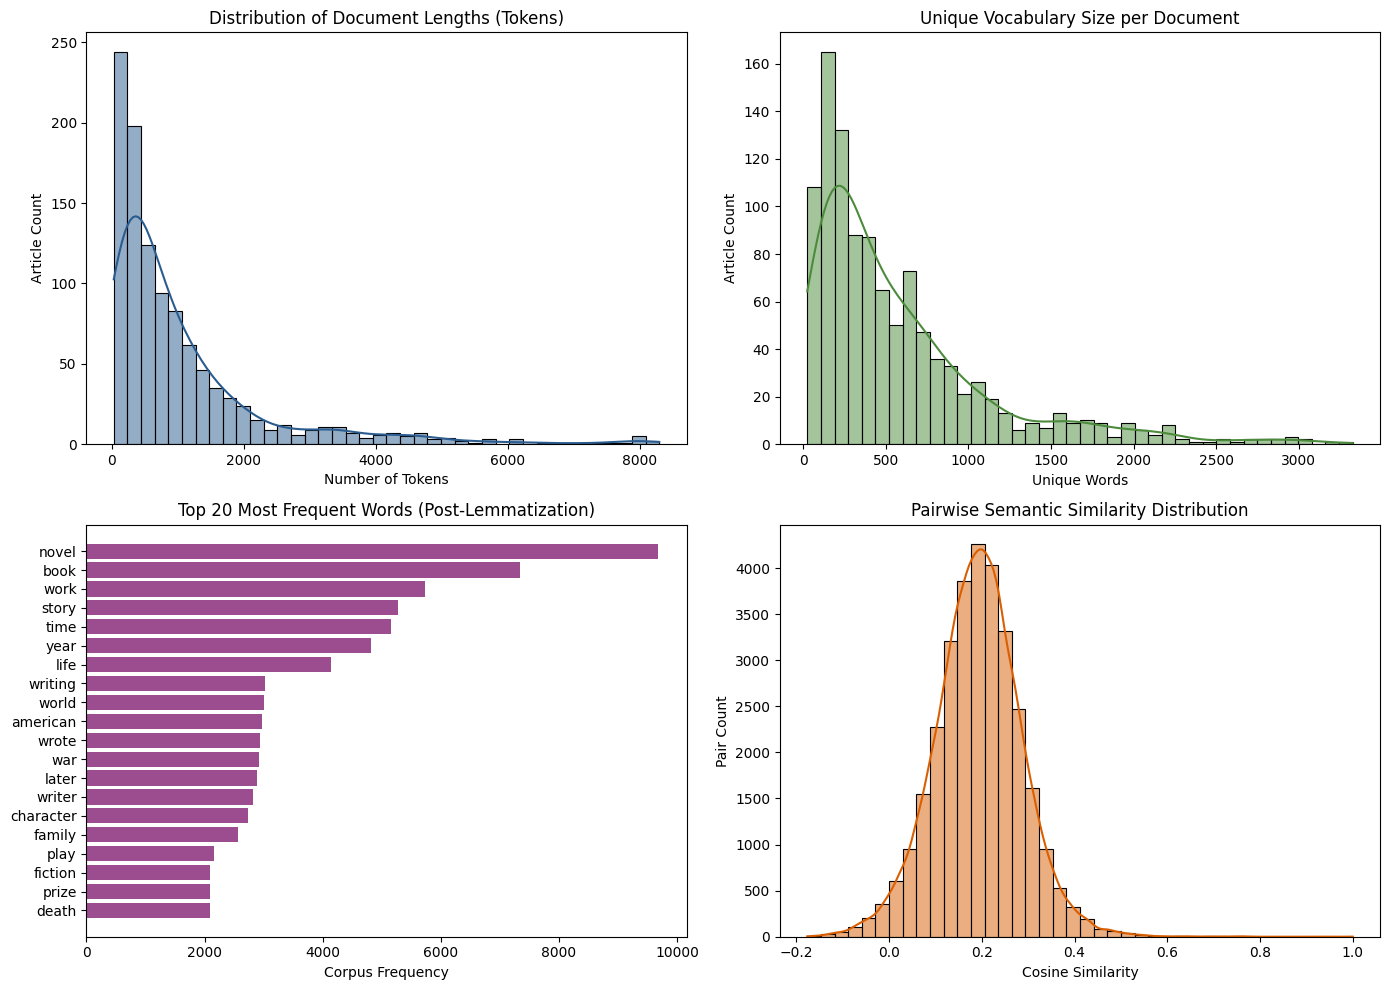

In [17]:
plot_corpus_statistics(df, dense_matrix)

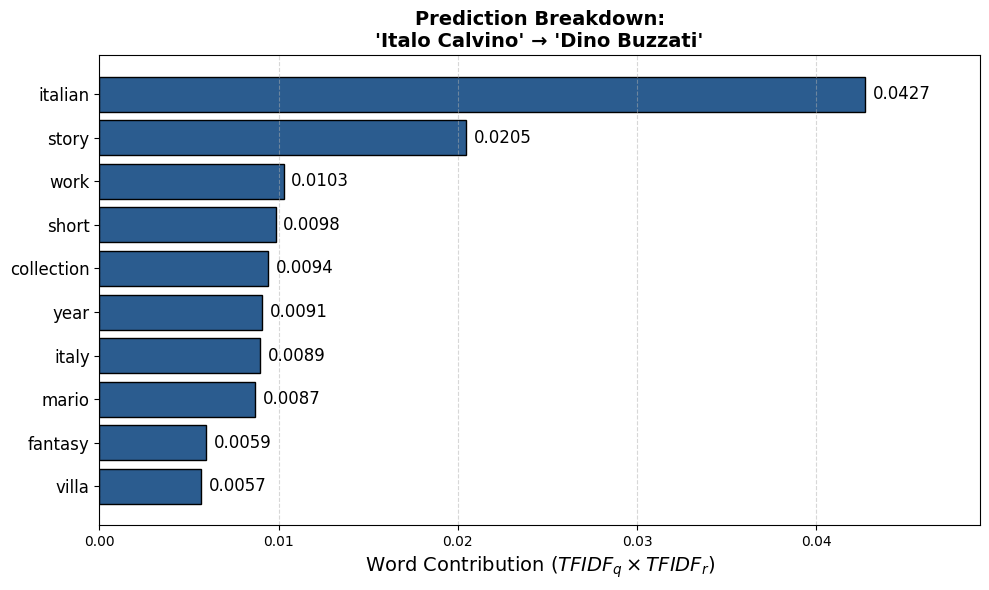

In [18]:
plot_prediction_breakdown(
    "https://en.wikipedia.org/wiki/Italo_Calvino",
    "https://en.wikipedia.org/wiki/Dino_Buzzati",
)

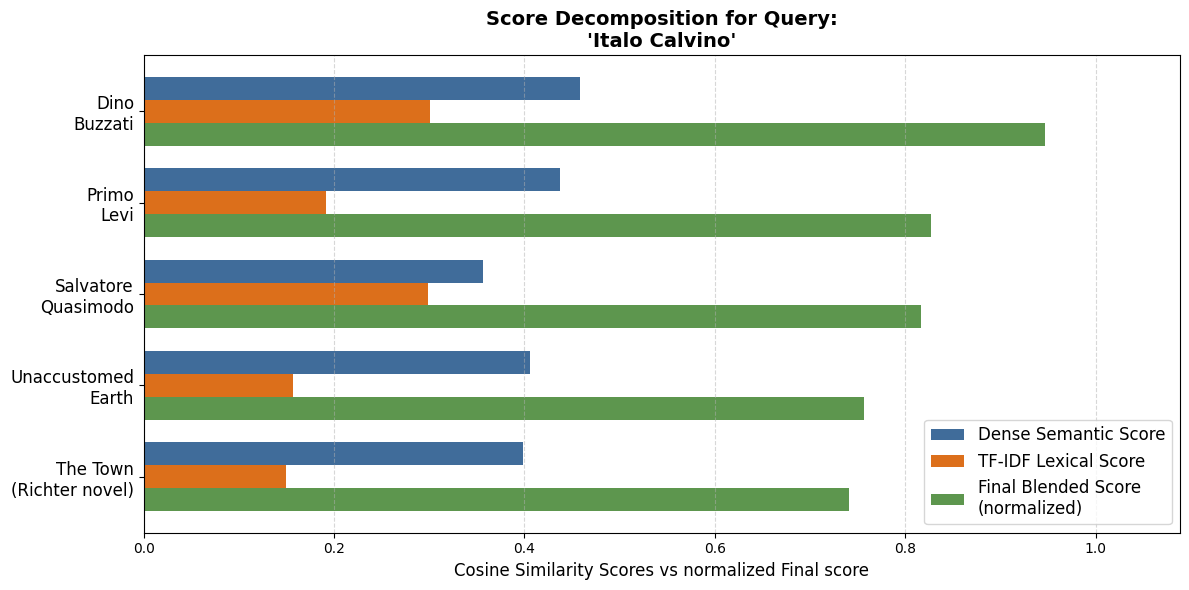

In [19]:
plot_score_decomposition("https://en.wikipedia.org/wiki/Italo_Calvino")

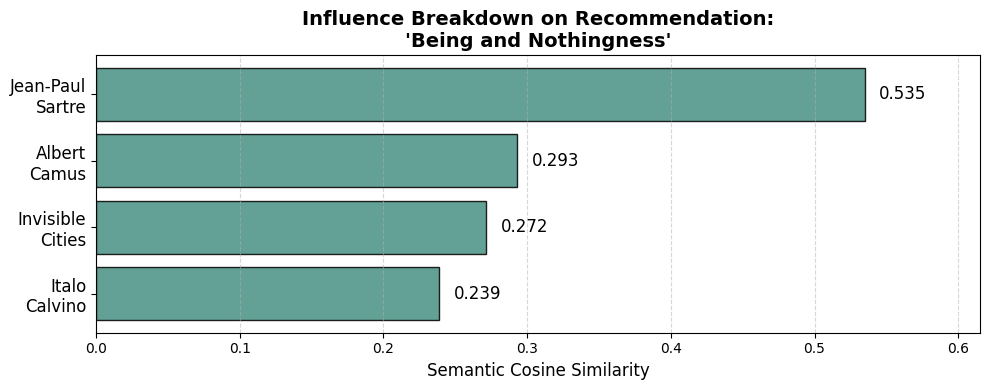

In [20]:
visited = [
    "https://en.wikipedia.org/wiki/Jean-Paul_Sartre",
    "https://en.wikipedia.org/wiki/Albert_Camus",
    "https://en.wikipedia.org/wiki/Italo_Calvino",
    "https://en.wikipedia.org/wiki/Invisible_Cities",
]

plot_user_profile_attribution(
    visited, "https://en.wikipedia.org/wiki/Being_and_Nothingness"
)